# Cross-solvent chemical shift transfer

Estimate a spectrum in a target solvent from measurements in a source solvent.

The experimental-reference model retrieves a similar molecular environment with paired measurements in both solvents. It adds the reference solvent difference to the query shift and returns the reference molecule and atom IDs alongside the estimate.

This tutorial loads the saved predictions, explains the input/output fields and evaluates the results. Use the final command to run the model on a new dataset.

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.solvent_transfer')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.solvent_transfer
Examples: 3


## Inputs and outputs

| Field | Meaning |
| --- | --- |
| `structure / nucleus` | Molecular connectivity and 1H or 13C. |
| `solvents` | Explicit source and target solvents that have paired references. |
| `source_ppm` | Measured source-solvent shifts in ppm. |

| Field | Meaning |
| --- | --- |
| `target_ppm / delta_ppm` | Estimated target shift and solvent difference from an independent reference. |
| `reference` | Reference identity, spectra/atom IDs, Tanimoto similarity and exclusions. |

Inspect the example records below. Long arrays show their length and first values; the downloadable JSON contains the complete arrays.

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "nucleus": "1H",
    "source_ppm": 1.45,
    "source_solvent": "CD3OD",
    "target_solvent": "acetone-d6",
    "query_connectivity": "C1CCCCC1"
  },
  "output": {
    "source_ppm": 1.45,
    "predicted_target_ppm": 1.3799999999999997,
    "predicted_delta_ppm": -0.07000000000000028,
    "source_solvent": "CD3OD",
    "target_solvent": "acetone-d6",
    "nucleus": "1H",
    "query_connectivity": "C1CCCCC1",
    "reference": {
      "identity": "C1COCCO1",
      "molecule_id": "10016061",
      "atom_id": "10093018",
      "source_ppm": 3.66,
      "target_ppm": 3.59,
      "source_spectrum_ids": [
        "20197666"
      ],
      "target_spectrum_ids": [
        "20197080"
      ]
    },
    "tanimoto_similarity": 0.125,
    "same_connectivity_excluded": true,
    "method": "nearest_paired_experimental_reference_delta",
    "model_kind": "retrieval_baseline_not_neural_model",
    "query_molecule_id": "10811",
    "query_atom_id": "10046537",
    "target_reference_pp

## Evaluate the predictions

Evaluate H and C shifts separately using MAE in ppm.

The table gives the dataset and metric for each run. The following calculation recomputes summary values from the plotted predictions.

In [3]:
display(Markdown(results_table(evidence, True)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | 13C | atoms | 140 |
| recorded evaluation | 13C | molecules | 13 |
| recorded evaluation | 13C | mae_ppm | 1.09429 |
| recorded evaluation | 13C | unchanged_shift_mae_ppm | 1.16371 |
| recorded evaluation | 13C | rmse_ppm | 1.90935 |
| recorded evaluation | 1H | atoms | 156 |
| recorded evaluation | 1H | molecules | 19 |
| recorded evaluation | 1H | mae_ppm | 0.137628 |
| recorded evaluation | 1H | unchanged_shift_mae_ppm | 0.135385 |
| recorded evaluation | 1H | rmse_ppm | 0.376179 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 3
}


## Visualize the result

Chemical shift transfer between solvents.

Compare the prediction with the reference and inspect the returned structures or peak positions. The plot is generated directly from the records loaded above.

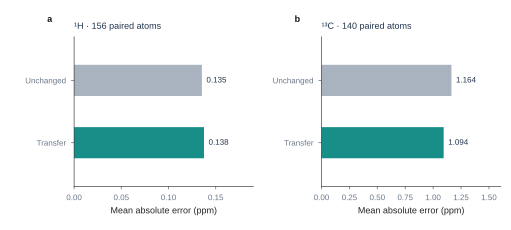

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.solvent_transfer', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## Run the model

Configure the runtime and weights following the task guide. Select this task in the benchmark runner to evaluate your dataset.

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.solvent_transfer --limit 8 --output results/nmr-solvent_transfer.json
```

[Task](../tasks/nmr-solvent_transfer.md) · [Quick start](../quickstart.md)



## References

- Steinbeck, C., Krause, S. & Kuhn, S. NMRShiftDB—Constructing a Free Chemical Information System with Open-Source Components. Journal of Chemical Information and Computer Sciences 43, 1733–1739 (2003). doi:10.1021/ci0341363. [Source](https://doi.org/10.1021/ci0341363)
